# Optimal transport for correlated and path-dependent event contracts

**Reproducible research prototype | October 2026**

This notebook computes *sharp model-independent price bounds* for a three-period binary event path, checks dual hedge certificates, and fits a maximum-entropy central pricing measure. All prices in the worked example are **hypothetical**, normalized to one unit of collateral, with zero discounting, fees, spreads and settlement risk.

## Research question

Given prices of single-event and pairwise event tokens, what prices can a coherent probability distribution assign to a path-dependent event that is not itself traded?

Let $\omega=(A,B,C)\in\{0,1\}^3$ index possible histories and let $q_\omega\geq0$ be their masses. For known payoff functions $h_j$, prices $p_j$, and new payoff $H$:

$$
\underline\pi(H)=\min_{q\geq0}\sum_{\omega}q_\omega H(\omega),\qquad
\overline\pi(H)=\max_{q\geq0}\sum_{\omega}q_\omega H(\omega),
$$

subject to $\sum_\omega q_\omega=1$ and $\sum_\omega q_\omega h_j(\omega)=p_j$.

These finite-state LPs are multi-marginal *optimal-transport / coupling* programs. They are not a unique forecast. The max-entropy estimate introduced below is a **separate statistical selection rule**, and must not be confused with a sharp no-arbitrage bound.

In [1]:
from itertools import product
import numpy as np
import pandas as pd
from scipy.optimize import linprog, minimize
from scipy.special import logsumexp
import matplotlib.pyplot as plt

states = np.asarray(list(product([0, 1], repeat=3)), dtype=int)
A, B, C = states.T
features = np.column_stack([np.ones(8), A, B, C, A*B, B*C, A*C]).astype(float)
feature_names = ['constant', 'A', 'B', 'C', 'AB', 'BC', 'AC']
market_prices = np.array([1.00, 0.60, 0.55, 0.45, 0.40, 0.30, 0.22])

payoffs = {
    'A then B then C (111)': (A*B*C).astype(float),
    'A then not B then C (101)': (A*(1-B)*C).astype(float)
}

print(pd.DataFrame({'state': [''.join(map(str, x)) for x in states],
                    **{name: features[:,i] for i,name in enumerate(feature_names)}}).to_string(index=False))

state  constant   A   B   C  AB  BC  AC
  000       1.0 0.0 0.0 0.0 0.0 0.0 0.0
  001       1.0 0.0 0.0 1.0 0.0 0.0 0.0
  010       1.0 0.0 1.0 0.0 0.0 0.0 0.0
  011       1.0 0.0 1.0 1.0 0.0 1.0 0.0
  100       1.0 1.0 0.0 0.0 0.0 0.0 0.0
  101       1.0 1.0 0.0 1.0 0.0 0.0 1.0
  110       1.0 1.0 1.0 0.0 1.0 0.0 0.0
  111       1.0 1.0 1.0 1.0 1.0 1.0 1.0


## 1. Linear-programming bounds with progressively more prices

Each market quote adds a linear constraint on the coupling. For an admissible set of traded payoffs, the extrema of an untraded path's expectation are computed with `scipy.optimize.linprog` (HiGHS).

In [2]:
def solve_bounds(payoff, feature_indices):
    eq_matrix = features[:, feature_indices].T
    eq_prices = market_prices[feature_indices]
    lo = linprog(payoff, A_eq=eq_matrix, b_eq=eq_prices,
                 bounds=(0, None), method='highs')
    hi = linprog(-payoff, A_eq=eq_matrix, b_eq=eq_prices,
                 bounds=(0, None), method='highs')
    if not lo.success or not hi.success:
        raise ValueError(f'Inconsistent constraints: {lo.message} | {hi.message}')
    return float(lo.fun), float(-hi.fun), lo.x, hi.x

stages = {
    'Single-event marginals only': [0, 1, 2, 3],
    'Plus AB and BC pairwise quotes': [0, 1, 2, 3, 4, 5],
    'Plus AC pairwise quote': [0, 1, 2, 3, 4, 5, 6],
}

rows = []
for stage_name, cols in stages.items():
    lo, hi, _, _ = solve_bounds(payoffs['A then B then C (111)'], cols)
    rows.append({'information': stage_name, 'lower': lo, 'upper': hi,
                 'width': hi-lo})
bound_table = pd.DataFrame(rows)
print(bound_table.to_string(index=False, float_format=lambda x:f'{x:.4f}'))
assert np.allclose(bound_table['lower'].to_numpy(), [0.0, 0.15, 0.15])
assert np.allclose(bound_table['upper'].to_numpy(), [0.45, 0.30, 0.22])

                   information  lower  upper  width
   Single-event marginals only 0.0000 0.4500 0.4500
Plus AB and BC pairwise quotes 0.1500 0.3000 0.1500
        Plus AC pairwise quote 0.1500 0.2200 0.0700


## 2. Price a different path: win / loss / win

$H_{101}=1\{A=1,B=0,C=1\}$ has the identity

$$
E_q[H_{101}]=E_q[AC]-E_q[ABC]=0.22-E_q[ABC].
$$

Therefore, once all six prices have been observed, the corresponding bounds are $[0,0.07]$. This is a genuinely path-specific payoff, not a terminal one-event claim.

In [3]:
for name, payoff in payoffs.items():
    lo, hi, q_lo, q_hi = solve_bounds(payoff, list(range(7)))
    print(f'{name}: [{lo:.6f}, {hi:.6f}]')
    assert np.isclose(payoff@q_lo, lo)
    assert np.isclose(payoff@q_hi, hi)

lo111, hi111, q_low, q_high = solve_bounds(payoffs['A then B then C (111)'], list(range(7)))
print('\nExtreme coupling at lower bound:')
print(pd.DataFrame({'state':[''.join(map(str, x)) for x in states], 'probability':q_low}).to_string(index=False))
print('\nExtreme coupling at upper bound:')
print(pd.DataFrame({'state':[''.join(map(str, x)) for x in states], 'probability':q_high}).to_string(index=False))

A then B then C (111): [0.150000, 0.220000]
A then not B then C (101): [0.000000, 0.070000]

Extreme coupling at lower bound:
state  probability
  000         0.17
  001         0.08
  010         0.00
  011         0.15
  100         0.13
  101         0.07
  110         0.25
  111         0.15

Extreme coupling at upper bound:
state  probability
  000         0.10
  001         0.15
  010         0.07
  011         0.08
  100         0.20
  101         0.00
  110         0.18
  111         0.22


## 3. Duality gives a portfolio hedge, not just abstract price bounds

For any payoff $H$, the LP upper dual is

$$
\min_{\alpha_0,\ldots,\alpha_m}
\left\{\alpha_0+\sum_j\alpha_jp_j:\quad
\alpha_0+\sum_j\alpha_j h_j(\omega)\geq H(\omega),\ \forall\omega\right\}.
$$

The dual parameters are quantities of (possibly short) traded claims and collateral making a **static superhedge** for $H$. For the all-ones path:

$$
AB+BC-B\ \leq\ ABC\ \leq\ AC.
$$

The lower inequality costs $0.40+0.30-0.55=0.15$; the upper inequality costs $0.22$. Verify these inequalities state by state.

In [4]:
ABC = payoffs['A then B then C (111)']
lower_hedge = A*B + B*C - B
upper_hedge = A*C
assert np.all(lower_hedge <= ABC + 1e-12)
assert np.all(ABC <= upper_hedge + 1e-12)
print('Lower subhedge cost:', .40+.30-.55)
print('Upper superhedge cost:', .22)
print('Synthetic quote 25%: AC minus ABC dominates zero statewise; modeled initial credit 3 cents.')
print('Synthetic quote 12%: ABC+B-AB-BC dominates zero statewise; modeled initial credit 3 cents.')
print('These are model consistency calculations, not observed or executable trades; common settlement, shorting and zero costs are assumed.')

Lower subhedge cost: 0.1499999999999999
Upper superhedge cost: 0.22
Synthetic quote 25%: AC minus ABC dominates zero statewise; modeled initial credit 3 cents.
Synthetic quote 12%: ABC+B-AB-BC dominates zero statewise; modeled initial credit 3 cents.
These are model consistency calculations, not observed or executable trades; common settlement, shorting and zero costs are assumed.


## 4. Choose a central coupling using maximum entropy

Bounds do **not** identify a unique true or fair probability. One defensible baseline is the maximum-entropy coupling

$$q^*=\arg\max_{q\in\mathcal Q}-\sum_\omega q_\omega\log q_\omega.$$

The interior solution has an exponential-family structure

$$q_\theta(\omega)=\frac{\exp\{\sum_j\theta_j h_j(\omega)\}}{\sum_{\omega'}\exp\{\sum_j\theta_j h_j(\omega')\}}.$$

Here all six moments, including pairwise terms, are matched exactly. The maximum-entropy estimate is a **model choice**, not an arbitrage price.

In [5]:
F = features[:, 1:]
target = market_prices[1:]

def dual_objective(theta):
    logits = F @ theta
    log_z = logsumexp(logits)
    q = np.exp(logits - log_z)
    return float(log_z - theta@target), F.T@q - target

result = minimize(dual_objective, np.zeros(F.shape[1]), jac=True,
                  method='BFGS', options={'gtol': 1e-11, 'maxiter': 2000})
logits = F @ result.x
q_entropy = np.exp(logits - logsumexp(logits))
assert np.linalg.norm(F.T@q_entropy - target, ord=np.inf) < 1e-8

p111 = float(ABC@q_entropy)
p101 = float(payoffs['A then not B then C (101)']@q_entropy)
conditional = p111 / market_prices[4]

print(f'Max-entropy P(111): {p111:.8f}')
print(f'Max-entropy P(101): {p101:.8f}')
print(f'Max-entropy P(C | A and B): {conditional:.8f}')
assert np.isclose(p111, 0.18448614805, atol=1e-7)
assert np.isclose(p101, 0.03551385195, atol=1e-7)
print(pd.DataFrame({'state':[''.join(map(str, x)) for x in states],
                    'maximum_entropy_probability':q_entropy}).to_string(index=False))

Max-entropy P(111): 0.18448615
Max-entropy P(101): 0.03551385
Max-entropy P(C | A and B): 0.46121537
state  maximum_entropy_probability
  000                     0.135514
  001                     0.114486
  010                     0.034486
  011                     0.115514
  100                     0.164486
  101                     0.035514
  110                     0.215514
  111                     0.184486


## 5. Visualize how additional pairwise observations shrink the transport interval

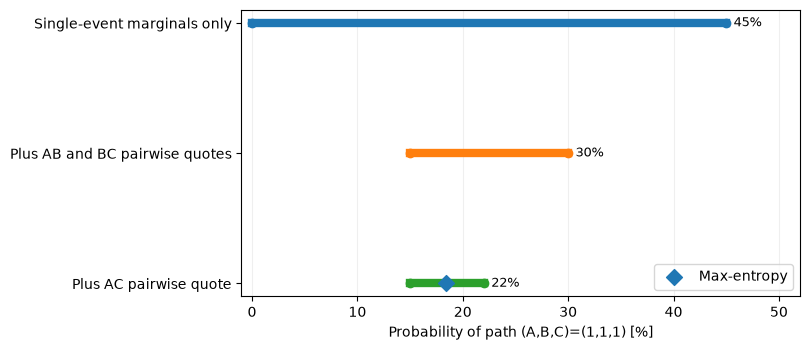

In [6]:
fig, ax = plt.subplots(figsize=(8.2, 3.6))
for i, row in enumerate(rows):
    ax.plot([row['lower']*100, row['upper']*100], [i,i], marker='o', linewidth=6)
    ax.text(row['upper']*100 + .7, i, f"{row['upper']*100:.0f}%", va='center', fontsize=9)
ax.scatter([p111*100], [2], marker='D', s=65, zorder=4, label='Max-entropy')
ax.set_yticks(range(3), labels=[r['information'] for r in rows])
ax.set_xlabel('Probability of path (A,B,C)=(1,1,1) [%]')
ax.set_xlim(-1, 52)
ax.invert_yaxis()
ax.grid(axis='x', alpha=.2)
ax.legend(loc='lower right')
fig.tight_layout()
plt.show()

## 6. Extension to underlying-linked event contracts: martingale OT

If event contracts are defined on an **actually traded underlying asset** $S$, such as a BTC digital event, use vanilla-option prices to recover time-$t$ risk-neutral marginal distributions $\mu_t$ (subject to smile calibration error). Then solve the **martingale** transport problem:

$$
\mathcal M(\mu_1,\ldots,\mu_T)=\left\{Q:\ S_t\sim\mu_t,
\quad E_Q[\widetilde S_{t+1}\mid\mathcal F_t]=\widetilde S_t\right\},
$$

$$\underline\pi_H=\inf_{Q\in\mathcal M}E_Q[D_T H(S_{0:T})],\qquad
\overline\pi_H=\sup_{Q\in\mathcal M}E_Q[D_T H(S_{0:T})].$$

$\widetilde S$ is the appropriately discounted tradable price. **Do not** impose the martingale condition on an indicator of whether an event has already occurred. The **price process** of a fixed event claim may be a martingale under an appropriate pricing measure; the event indicator process itself generally is not.

For claims monitored continuously (e.g., first barrier touch), observations at only three dates cannot determine whether the barrier was crossed between dates: additional regularity/model assumptions or true continuous-time robust bounds are needed.

## Next research stages

1. Add bid/ask interval calibration, liquidity, execution fees, margin, funding and oracle risk.
2. Use held-out event paths to compare independent-copula, Ising, max-entropy, historical transition, and Wasserstein-robust priors.
3. For asset-linked event contracts, fit arbitrage-free option surfaces and add martingale constraints.
4. For many-period histories, exploit flow/state-space factorization and entropic regularization to mitigate the exponential path explosion.
5. Measure out-of-sample interval coverage and net executable spreads rather than only backtested midpoint alpha.

## References

- Beiglboeck, Henry-Labordere, Penkner (2013), *Model-independent bounds for option prices: a mass transport approach*. https://doi.org/10.1007/s00780-013-0205-8
- Guo and Loeper (2021), *Path dependent optimal transport and model calibration on exotic derivatives*. https://doi.org/10.1214/20-AAP1617
- Ansari, Luetkebohmert, Neufeld, Sester (2024), *Improved robust price bounds for multi-asset derivatives under market-implied dependence information*. https://doi.org/10.1007/s00780-024-00539-z
- Engstroem, Kaellblad, Karlsson (2025), *Computation of robust option prices via structured multimarginal martingale optimal transport*. https://doi.org/10.1137/24M1670573
- Shi and Zhai (October 2026), *Combinatorial Arbitrage in Prediction Markets*. https://arxiv.org/abs/2610.23517
- Rana et al. (2026), *ParlayMarket: Automated Market Making for Parlay-style Joint Contracts*. https://arxiv.org/abs/2603.22596
- Gnosis Conditional Tokens, developer guide. https://conditional-tokens.readthedocs.io/en/latest/developer-guide.html